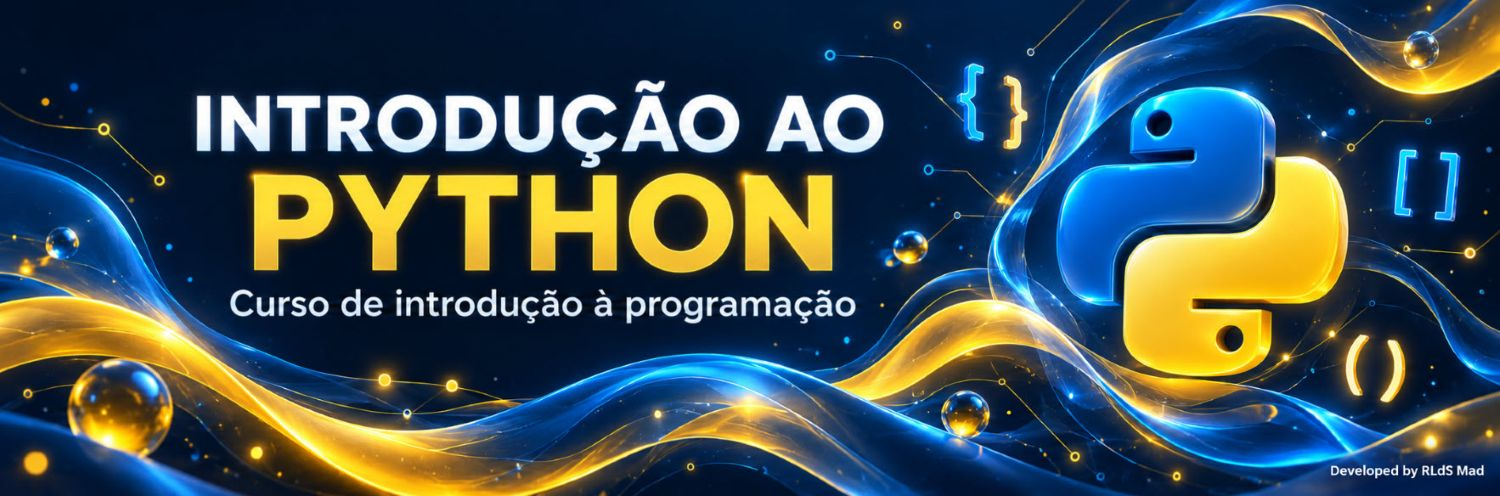

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python_v2/nivel_1_introducao/RLdS_17_Ficheiros.ipynb)


# Capítulo 17 – Ficheiros

A memória principal do computador (RAM) é volátil. Quando o computador é desligado os dados em memória são perdidos. Para manter os dados armazenados e acessíveis posteriormente, mesmo depois de reiniciar o computador, os dados são guardados em disco, em ficheiros.

O que esses dados representam depende do seu formato, que normalmente é representado por uma extensão. Por exemplo, um ficheiro que possui uma extensão `.pdf` provavelmente está no formato PDF (*Portable Document Format*).

Um ficheiro é um conjunto de bytes usado para guardar dados na memória não-volátil (disco). Estes dados são organizados num formato específico e podem ser tão simples como um ficheiro de texto ou complicados como um binário (programa executável). Internamente, tudo é guardado em `binário` (`0 e 1`).

A gestão dos ficheiros é feita, na maioria dos sistemas computacionais modernos, pelo sistema de ficheiros.

Do ponto de vista do programador, um ficheiro tem:

- **Dados:** o conteúdo do ficheiro;
- **Metadados:** informação sobre o ficheiro (nome, tamanho, datas, permissões), guardada pelo sistema de ficheiros.

Quando lemos um ficheiro, o fim do ficheiro (*End of File*, EOF) é detetado quando já não há mais dados para ler.

Para aceder a um ficheiro, é necessário indicar o seu caminho. O caminho do ficheiro é uma `string` que representa a sua localização. Ele é dividido em três partes principais:

- **Caminho da pasta/diretoria:** A localização da pasta de ficheiros no sistema de ficheiros onde as pastas subsequentes são separadas por uma barra `/` (Linux/Unix) ou barra invertida `\` (Windows), precedido da unidade de disco (por exemplo, `C:\`).

- **Nome do ficheiro:** Representa o nome do ficheiro.
- **Extensão:** O final do caminho do ficheiro prefixado com um ponto `.` usado para indicar o seu tipo, na maioria dos casos associado a uma aplicação específica.

## Operações em ficheiros

O manuseamento básico de ficheiros consiste em três passos:

- `Abrir o ficheiro e atribuí-lo a uma variável.`
- `Aceder ao ficheiro:`
    - *Ler do ficheiro (read access)*
    - *Escrever para o ficheiro (write access)*
- `Fechar o ficheiro`


A função **open()** pode ser utilizada para `abrir um ficheiro`, e para tal é necessário indicar o caminho onde o ficheiro está localizado, caso este não esteja localizado na mesma diretoria/pasta do programa. 

Para as `demais operações` existem alguns `métodos`, tais como `.write()`, `.read()` ou `.close()`. Existem outros módulos que permitem funções adicionais para tipos de ficheiros especiais, tais como *.csv* ou *.json*, por exemplo.

Adicionalmente, o modo pelo qual o ficheiro é aberto pode ser opcional. Abaixo a **lista** com os `modos` mais importantes:

| Modo | Descrição | Dá erro se… | Atenção |
| :--- | :-------- | :---------- | :------ |
| r    | Só leitura | o ficheiro não existir, ou se tentarmos escrever | |
| w    | Só escrita; cria o ficheiro se não existir | tentarmos ler | **Apaga** o conteúdo existente |
| a    | Acrescenta (*append*) conteúdo no fim | tentarmos ler | |
| x    | Cria um ficheiro novo para escrita | o ficheiro já existir | Evita apagar ficheiros por engano |
| r+   | Leitura e escrita | o ficheiro não existir | |
| w+   | Escrita e leitura; cria o ficheiro se não existir | | **Apaga** o conteúdo existente |

Quando se acrescenta um *b* ao modo (por exemplo, `"rb"`), o ficheiro é aberto em modo binário (bytes) e não em modo texto. Se o modo não for especificado o valor padrão será `"r"`.

**Recomendação:** Especificar *sempre* um modo. Isto simplifica a manutenção do programa. O modo é sempre indicado como uma string, por exemplo `"r"` ou `'r'`, e não `r`.

**Recomendação:** em modo texto, indica também a codificação, `encoding="utf-8"`. Sem ela, o Python usa a codificação do sistema operativo, que no Windows pode não ser UTF-8, e os acentos podem aparecer trocados ou dar erro.



### `Abrir um ficheiro em modo escrita`

O **exemplo abaixo** abre o ficheiro em modo escrita (`write mode`). Se o ficheiro não existir na pasta onde o programa está a ser executado, é criado. Neste exemplo, o ficheiro não terá qualquer conteúdo: apenas é criado.

**Importante:** num *notebook*, se não for indicado um caminho, o ficheiro é criado na pasta de trabalho do notebook. No Colab, essa pasta é `/content`: os ficheiros aparecem no painel **Ficheiros** (ícone 📁, à esquerda), mas são **apagados quando a sessão termina**. Se quiseres guardá-los, descarrega-os.


In [ ]:
# O ficheiro é aberto em modo escrita
file = open("ficheiro_teste.txt", "w", encoding="utf-8")

# Fecha o ficheiro
file.close()

### `Abrir um ficheiro em modo leitura`

No **próximo exemplo**, o ficheiro criado anteriormente é aberto em modo leitura e fechado novamente.

**Apaga** o ficheiro `ficheiro_teste.txt` (no Colab, pelo painel 📁) e executa novamente o código abaixo. Qual será o resultado? (Dica: lembra-te do `FileNotFoundError` do capítulo 16.)


In [ ]:
# O ficheiro é aberto em modo leitura
file = open("ficheiro_teste.txt", "r", encoding="utf-8")

# Fecha o ficheiro
file.close()


### `Abrir um ficheiro existente em modo escrita`

**Abre** o ficheiro `ficheiro_teste.txt` com um editor de texto (no Colab, faz duplo clique sobre ele no painel 📁), escreve alguns caracteres e linhas, guarda e fecha o ficheiro.

Executa novamente o primeiro exemplo. Verifica o conteúdo do ficheiro. O que aconteceu?


### `Abrir ficheiros com with`

Como vimos nos exemplos anteriores, um ficheiro é sempre fechado depois de aberto. Deixar um ficheiro aberto poderá causar erros. 

Para evitar esquecimentos, utiliza-se a instrução `with`. Depois de sair do bloco `with`, o ficheiro é fechado automaticamente. Isto acontece mesmo que ocorra um erro dentro do bloco.

Um ficheiro é organizado sequencialmente. E para processar sequências, iterar sobre os seus conteúdos, ou seja linha a linha de um ficheiro, utiliza-se o `for`, como mencionado em outras ocasiões.

A célula seguinte cria o ficheiro `academia.txt`, que vamos usar nos exemplos. Depois, vejamos como lê-lo.

In [ ]:
# Cria o ficheiro de exemplo academia.txt
with open("academia.txt", "w", encoding="utf-8") as file:
    file.write("Curso de Introdução ao Python\n")
    file.write("Capítulo 17: manipulação de ficheiros\n")
    file.write("Os ficheiros guardam dados de forma permanente.\n")
    file.write("O Python consegue ler um ficheiro linha a linha.\n")
    file.write("Bom estudo!\n")
print("Ficheiro academia.txt criado.")

In [ ]:
# Abrir o ficheiro com open
with open("academia.txt", "r", encoding="utf-8") as file:
    # lê o ficheiro linha a linha e imprime o resultado
    for line in file:
        print(line)

# O ficheiro é fechado automaticamente


O resultado do exemplo acima foi o esperado? Que tal comparar o resultado da impressão com o conteúdo do ficheiro?

Linhas em branco foram adicionadas entre as linhas existentes no ficheiro durante a impressão. 

Isto ocorre porque no final de cada linha há uma quebra de linha `\n`. Isto é apenas visível indiretamente, porque o texto continua na próxima linha. Como a função `print()` acrescenta outra quebra de linha no fim, aparece uma linha em branco.

Este comportamento pode ser corrigido de várias maneiras. Uma delas é definir o parâmetro `end=""` na função `print()`.

A alternativa é utilizar o método `strip()` para remover os espaços, tabulações e quebra de linhas no início e fim da string. Este método é muito usado para limpar dados introduzidos pelo utilizador. Indicando um argumento, é possível remover outros caracteres, por exemplo `strip(".")`.

Outras alternativas são `.lstrip()` ou `.rstrip()`, que removem os caracteres apenas à esquerda ou à direita da string, respetivamente.


In [ ]:
# Abrir o ficheiro com open
with open("academia.txt", "r", encoding="utf-8") as file:
    # lê o ficheiro linha a linha e imprime o resultado
    for line in file:
        print(line, end="")
        #print(line.strip())

# O ficheiro é fechado automaticamente


O que acontece se executares o loop `for` duas vezes?


In [ ]:
# Abrir o ficheiro com open
with open("academia.txt", "r", encoding="utf-8") as file:
    # lê o ficheiro linha a linha e imprime o resultado
    print("Primeira execução!")
    for line in file:
        print(line, end="")
        #print(line.strip())
        
    print("\nSegunda execução!")
    for line in file:
        # print(line, end="")
        print(line.strip())



Ao ler um ficheiro, o `cursor de leitura` ou `ponteiro de leitura` é movido carácter a carácter, percorrendo assim todo o ficheiro. Quando o ponteiro chega ao *fim do ficheiro a leitura não continua* porque não é feito um reposicionamento do ponteiro.

O método `.seek(offset, whence)` pode ser utilizado para reposicionar o `cursor de leitura`.

- `Offset:` Número de posições (bytes) para mover o ponteiro
- `whence:` Define a posição de referência no ficheiro

A posição de referência aceita três valores:
- `0:` posiciona no início do ficheiro 
- `1:` posiciona na posição atual do ficheiro 
- `2:` posiciona no fim do ficheiro


Já o método `.tell()` indica em que posição o cursor de leitura se encontra.


In [ ]:
with open("academia.txt", "r", encoding="utf-8") as file:
    # lê o ficheiro linha a linha e imprime o resultado
    print("Primeira execução!")
    for line in file:
        print(line, end="")
        #print(line.strip())
    print("Posição: ", file.tell())
    pos_file = file.seek(15,0)
    print(pos_file)
    
    print("\nSegunda execução!")
    for line in file:
        # print(line, end="")
        print(line.strip())


A **tabela** a seguir apresenta a `lista` completa dos `métodos` de ficheiros disponíveis em Python.

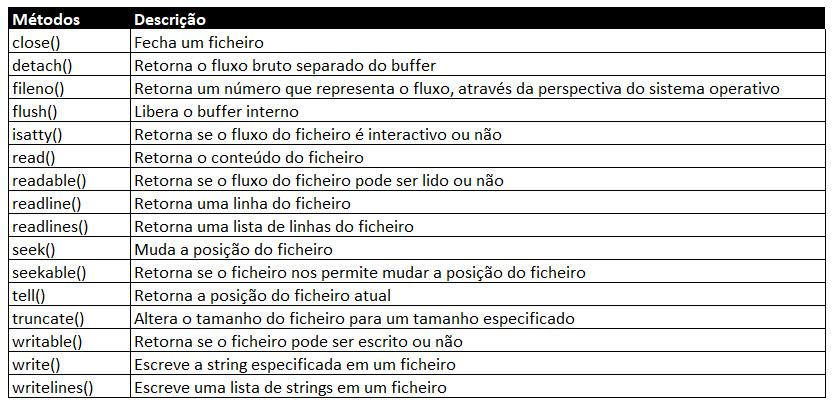

### `Escrever num ficheiro`

Os métodos `.write()` e `.writelines()` são utilizados para escrever nos ficheiros: `.write()` escreve uma string e `.writelines()` escreve todas as strings de uma lista (sem acrescentar quebras de linha). A **célula abaixo** exemplifica cada um dos métodos.

In [ ]:
with open("ficheiro.txt", "w", encoding="utf-8") as file:
    file.write("Olá futuros programadores de Python!\n")
    file.write("O meu nome é ")
    file.write("Darth Vader!\n")
    file.writelines(["Sou o pai da Leia!", " ", "E do Luke!"])
    file.writelines(["\nEstou a caminho do vosso planeta!", "\nAté já!"])



E a **próxima célula**, uma vez mais, demonstra a `leitura de um ficheiro`. Neste caso a leitura será feita no ficheiro criado.


In [ ]:
file = open('ficheiro.txt', "r", encoding="utf-8")
data = file.read(40)
print(data)
data = file.read(24)
print(data)
for line in file:
    print(line.strip())
file.close()


No **exemplo abaixo** algumas `operações de leitura e posicionamento` no ficheiro.

In [ ]:
# Posiciona o cursor na posição 26, a contar do início, e lê o resto da linha
with open("ficheiro.txt", "r", encoding="utf-8") as file:
    file.seek(26)
    print(file.tell())
    print(file.readline())

# Abre o ficheiro em modo binário ("rb"): lê bytes em vez de texto
with open("ficheiro.txt", "rb") as file:
    # seek(-18, 2): recua 18 bytes a partir do fim do ficheiro (referência 2 = fim)
    file.seek(-18, 2)
    print(file.tell())
    print(file.readline())                  # devolve bytes: b'...'
    print(file.readline().decode("utf-8"))  # decode() converte os bytes em texto

### `Exercício 1`

Cria um ficheiro chamado `numeros.txt` e escreve nele os números de 0 a 100, um em cada linha.

In [ ]:
# Utiliza esta célula para o exercício 1


<details>
<summary><b>Ver uma solução possível</b></summary>

```python
with open("numeros.txt", "w", encoding="utf-8") as ficheiro:
    for numero in range(101):
        ficheiro.write(f"{numero}\n")
print("Ficheiro criado.")
```

</details>


### `Exercício 2`

Abre o ficheiro criado no exercício 1, `numeros.txt`, e lê-o linha a linha (há um número por linha). Imprime cada número e, no fim, a soma de todos os números (deve dar 5050).

In [ ]:
# Utiliza esta célula para o exercício 2


<details>
<summary><b>Ver uma solução possível</b></summary>

```python
soma = 0
with open("numeros.txt", "r", encoding="utf-8") as ficheiro:
    for linha in ficheiro:
        numero = int(linha.strip())
        print(numero)
        soma += numero
print("Soma:", soma)   # 5050
```

</details>


## Leitura recomendada

https://docs.python.org/3/library/functions.html#open

https://realpython.com/working-with-files-in-python/